# Gasto en salud como porcentaje del PIB

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Carga, metadatos y calidad
[Indicador original](https://ourworldindata.org/grapher/total-healthcare-expenditure-gdp). Se utiliza la copia local
registrada con huella SHA-256. Los códigos de tres letras delimitan las entidades comparadas;
se excluyen agregados y faltantes del indicador. El metadato determina la unidad.

In [2]:
bruto = leer_owid("total-healthcare-expenditure-gdp")
display(bruto.head())
print("Dimensiones:", bruto.shape)
display(bruto.isna().sum().to_frame("faltantes"))
meta = metadatos("total-healthcare-expenditure-gdp")["columns"]["current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct"]
print("Unidad:", meta.get("unit"), "Fuente:", meta.get("citationShort"))
datos = solo_paises(indicador("total-healthcare-expenditure-gdp", "current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct", "percentage_health"))
datos = datos.dropna(subset=["percentage_health"]).sort_values(["entity", "year"])
assert not datos.duplicated(["entity", "year"]).any()

,entity,code,year,current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct
0,Afghanistan,AFG,2002,9.443391
1,Afghanistan,AFG,2003,8.941258
2,Afghanistan,AFG,2004,9.808474
3,Afghanistan,AFG,2005,9.948289
4,Afghanistan,AFG,2006,10.622766


Dimensiones: (4756, 4)


,faltantes
entity,0
code,0
year,0
current_health_expenditure__che__as_percentage_of_gross_domestic_product__gdp__pct,0


Unidad: % Fuente: World Health Organization – Global Health Observatory (2026) – with minor processing by Our World in Data


## 2. Serie de México y comparación internacional
Se conserva un periodo común 2000-2023 y se comparan las mismas unidades.
El gasto como porcentaje del PIB mide una proporción, no dólares gastados por habitante;
el PIB por persona mide producción promedio, no el ingreso de cada hogar.

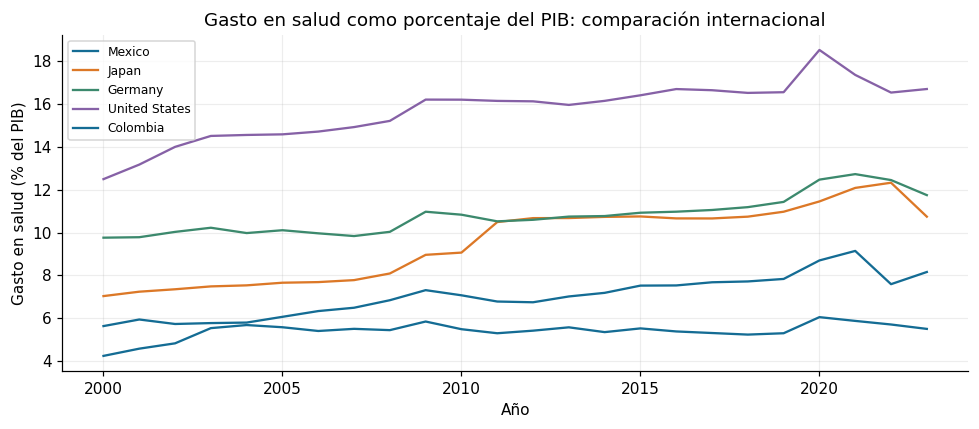

,year,percentage_health
2757,2018,5.238214
2758,2019,5.301346
2759,2020,6.052486
2760,2021,5.876780
2761,2022,5.709197
2762,2023,5.503987


In [3]:
paises = ["Mexico", "Japan", "Germany", "United States", "Colombia"]
recorte = datos.loc[datos.year.between(2000, 2023) & datos.entity.isin(paises)]
for pais in paises:
    serie = recorte.loc[recorte.entity.eq(pais)]
    plt.plot(serie.year, serie["percentage_health"], label=pais)
plt.xlabel("Año")
plt.ylabel("Gasto en salud (% del PIB)")
plt.title("Gasto en salud como porcentaje del PIB: comparación internacional")
plt.legend(fontsize=8)
guardar_figura("04_healthcare_spending")
mx = recorte.loc[recorte.entity.eq("Mexico")]
display(mx[["year", "percentage_health"]].tail(6))

## 3. Ordenar un corte comparable (2021)
Se ordena un solo año y se muestran las diez entidades con valores más altos de las
disponibles. Este ranking no representa bienestar ni calidad sanitaria por sí mismo.

In [4]:
corte = datos.loc[datos.year.eq(2021)].copy()
top = corte.nlargest(10, "percentage_health")
display(top[["entity", "year", "percentage_health"]].round(2))
guardar_tabla(datos, "04_healthcare_spending.csv")
ultimo = mx.iloc[-1]
primero = mx.iloc[0]
display(Markdown(f"México pasa de **{primero['percentage_health']:.2f}** en {int(primero.year)} "
                 f"a **{ultimo['percentage_health']:.2f}** en {int(ultimo.year)}. "
                 f"El corte de 2021 contiene **{len(corte)} entidades** con dato válido."))

,entity,year,percentage_health
19,Afghanistan,2021,21.51
4423,Tuvalu,2021,18.57
4541,United States,2021,17.35
3157,Niue,2021,15.08
3277,Palau,2021,14.55
1099,Cuba,2021,13.79
2437,Liberia,2021,13.27
1696,Germany,2021,12.72
2688,Marshall Islands,2021,12.49
787,Canada,2021,12.38


CSV guardado: U3_1_modelos_ml/data/processed/04_healthcare_spending.csv (4,588 filas)


México pasa de **4.24** en 2000 a **5.50** en 2023. El corte de 2021 contiene **195 entidades** con dato válido.

## 4. Conclusión
La trayectoria muestra variaciones anuales que se perderían al comparar solo extremos.
Una variación de la proporción de gasto también puede reflejar cambios del denominador
(PIB), y no únicamente cambios de gasto. Las diferencias internacionales se describen;
atribuirlas a una política requiere indicadores adicionales y otro diseño de análisis.